# Continuous DiD

Standard difference-in-differences compares treated and untreated groups. But treatment
is often not all-or-nothing. In a **job training programme**, some workers receive one
hour of training, others three, a few six. Lumping every trained worker together
answers "does training help?" and throws away the more useful question: **how do
earnings respond to the amount of training?** Continuous DiD (Callaway, Goodman-Bacon &
Sant'Anna 2024) estimates that dose-response curve.

**What you'll learn**

- Which parameters a continuous treatment defines, and which assumption each one needs
- How to fit `ContinuousDiD` and read the overall effect and the dose-response curves
- How to check pre-treatment behaviour with an event study
- What the spline settings, the control group and the bootstrap change
- What is lost by treating the dose as binary

**Prerequisites:** [Staggered DiD](02_staggered_did.ipynb) and
[Parallel Trends Diagnostics](04_parallel_trends.ipynb).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from diff_diff import (
    CallawaySantAnna,
    ContinuousDiD,
    generate_continuous_did_data,
    plot_event_study,
)

## What it estimates and assumes

Consider the training programme. Workers receive different amounts of training, and the
question is whether more training leads to higher earnings. Two shortcuts fail:

- **Treating the dose as binary** tells you whether *any* training helps, not whether
  *more* helps more.
- **Putting the dose into a two-way fixed effects regression** returns a single slope
  that weights dose groups in ways that are hard to interpret and can be negative, the
  same problem that affects binary two-way fixed effects under staggered adoption.

**Target parameters.** A continuous treatment defines several:

| Parameter | Meaning in the training example | Needs |
|---|---|---|
| ATT(d) | Earnings gain from *d* hours of training compared with none, averaged over all trained workers | strong parallel trends |
| ACRT(d) | Gain from one more hour at level *d*: the slope of ATT(d) | strong parallel trends |
| Overall ATT | Average gain of trained workers compared with no training, at the doses they actually received | parallel trends |
| Overall ACRT | Average gain from one more hour, over trained workers | strong parallel trends |

**Identifying assumptions.** There are two levels.

- **Parallel trends:** without training, earnings would have evolved in the same way for
  workers at every dose and for untrained workers. This is the usual assumption,
  required dose group by dose group. It identifies the effect of dose *d* **on the
  workers who actually received dose *d***, and the average of those effects, which is
  the overall ATT. It does not license comparing one dose group's effect with another's:
  the groups may differ in how much they benefit.
- **Strong parallel trends:** in addition, workers do not sort into doses according to
  how much they would gain. Formally, the average change in earnings that the workers
  at dose *d* experience is what all trained workers would have experienced had they
  received *d*. It is an assumption about outcomes *under treatment*, not only about
  untreated paths. Under it the dose-response curve ATT(d), its slope ACRT(d) and
  comparisons across doses have a causal reading.

Both also need **no anticipation**, and treatment that is **absorbing** with a dose that
does not change over time.

**What would violate them.** For parallel trends, the usual threats: trained workers
already on a different earnings path. For strong parallel trends, selection on gains:
if the workers who expect training to pay off most are the ones who take the most
hours, the curve mixes "more hours" with "the kind of worker who chooses more hours" and
overstates the return to an extra hour.

## Simulated data

A balanced panel of 500 workers over 4 periods. Seventy percent start training in period
2 and the rest are never trained. Each trained worker's dose is drawn from a log-normal
distribution. The true effect is **ATT(d) = 1 + 2d**: a gain of 1 for any training, plus
2 for every hour. Doses are assigned independently of gains, so strong parallel trends
holds.

In [2]:
ATT_INTERCEPT = 1.0
ATT_SLOPE = 2.0  # the true ACRT at every dose

data = generate_continuous_did_data(
    n_units=500,
    n_periods=4,
    cohort_periods=[2],
    never_treated_frac=0.3,
    att_function="linear",
    att_intercept=ATT_INTERCEPT,
    att_slope=ATT_SLOPE,
    seed=42,
)

treated_doses = data.loc[data["first_treat"] > 0].groupby("unit")["dose"].first()
TRUE_ATT = ATT_INTERCEPT + ATT_SLOPE * treated_doses.mean()

print(f"{data['unit'].nunique()} workers, {data['period'].nunique()} periods")
print(f"Never trained: {(data.groupby('unit')['first_treat'].first() == 0).sum()}")
print()
print("Dose among trained workers:")
print(treated_doses.describe()[["min", "25%", "50%", "mean", "75%", "max"]].round(2).to_string())
print()
print(f"True overall ATT  (1 + 2 x mean dose): {TRUE_ATT:.3f}")
print(f"True overall ACRT:                     {ATT_SLOPE:.3f}")

500 workers, 4 periods
Never trained: 150

Dose among trained workers:
min     0.46
25%     1.18
50%     1.61
mean    1.84
75%     2.21
max     7.08

True overall ATT  (1 + 2 x mean dose): 4.675
True overall ACRT:                     2.000


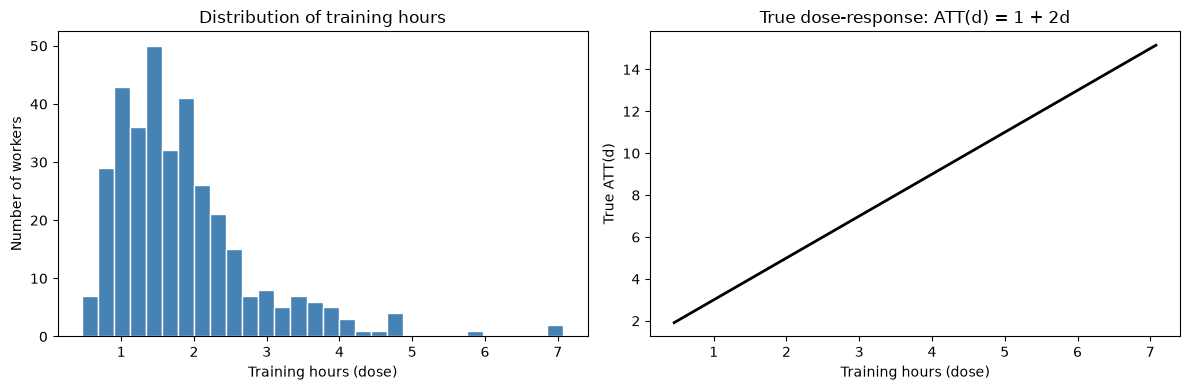

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(treated_doses, bins=30, edgecolor="white", color="steelblue")
axes[0].set_xlabel("Training hours (dose)")
axes[0].set_ylabel("Number of workers")
axes[0].set_title("Distribution of training hours")

dose_range = np.linspace(treated_doses.min(), treated_doses.max(), 100)
axes[1].plot(dose_range, ATT_INTERCEPT + ATT_SLOPE * dose_range, "k-", linewidth=2)
axes[1].set_xlabel("Training hours (dose)")
axes[1].set_ylabel("True ATT(d)")
axes[1].set_title("True dose-response: ATT(d) = 1 + 2d")

plt.tight_layout()
plt.show()

## Fitting the estimator

`fit()` takes the usual columns plus `dose`. The overall parameters and the
dose-response curves are computed in the same fit. Inference is at the unit level.

In [4]:
fit_args = dict(outcome="outcome", unit="unit", time="period", first_treat="first_treat", dose="dose")

results = ContinuousDiD(seed=42).fit(data, **fit_args)

print(results.summary())

                     Continuous Difference-in-Differences Results                    
                      (Callaway, Goodman-Bacon & Sant'Anna 2024)                     

Total observations:                  2000
Treated units:                        350
Control units:                        150
Treatment cohorts:                      1
Time periods:                           4
Control group:                 never_treated
Treatment type:                continuous
B-spline degree:                        3
Interior knots:                         0
Base period:                      varying
Anticipation:                           0

-------------------------------------------------------------------------------------
                              Overall Summary Parameters                             
-------------------------------------------------------------------------------------
Parameter           Estimate    Std. Err.     t-stat      P>|t|   Sig.
--------------------------------

In [5]:
acrt_lower, acrt_upper = results.overall_acrt_conf_int

print(f"{'':<14} {'estimate':>9} {'95% CI':>20} {'truth':>8}")
print(f"{'Overall ATT':<14} {results.att:>9.3f} {f'[{results.conf_int[0]:.3f}, {results.conf_int[1]:.3f}]':>20} {TRUE_ATT:>8.3f}")
print(f"{'Overall ACRT':<14} {results.overall_acrt:>9.3f} {f'[{acrt_lower:.3f}, {acrt_upper:.3f}]':>20} {ATT_SLOPE:>8.3f}")

                estimate               95% CI    truth
Overall ATT        4.547       [4.238, 4.855]    4.675
Overall ACRT       2.149       [1.958, 2.339]    2.000


Both intervals contain the truth: 4.55 [4.24, 4.86] against a true overall ATT of 4.68,
and 2.15 [1.96, 2.34] against a true overall ACRT of 2.0.

The summary labels them `ATT_glob` and `ACRT_glob`; in code they are `results.att` and
`results.overall_acrt`.

- The **overall ATT** answers "how much more do trained workers earn, on average, than
  they would have without training?". It is computed as the binary
  treated-against-untreated comparison, so it needs only parallel trends.
- The **overall ACRT** answers "what is one more hour worth, on average?". It is a
  statement about moving along the curve, so it needs strong parallel trends.

## Dose-response curves

The estimator evaluates ATT(d) and ACRT(d) on a grid of doses, by default the 10th to
the 99th percentile of the observed doses. The curves are in `results.dose_response_att`
and `results.dose_response_acrt`.

In [6]:
att_curve = results.dose_response_att.to_dataframe()
att_curve["true_att"] = ATT_INTERCEPT + ATT_SLOPE * att_curve["dose"]

print(f"Dose grid: {att_curve['dose'].min():.2f} to {att_curve['dose'].max():.2f}, {len(att_curve)} points")
print(att_curve.iloc[::10].round(3).to_string(index=False))

Dose grid: 0.90 to 4.80, 90 points
 dose  effect    se  conf_int_lower  conf_int_upper  t_stat  p_value  true_att
0.897   2.539 0.142           2.261           2.818  17.883      0.0     2.795
1.072   2.954 0.128           2.703           3.204  23.108      0.0     3.144
1.294   3.459 0.122           3.221           3.698  28.402      0.0     3.588
1.427   3.753 0.122           3.514           3.993  30.719      0.0     3.853
1.612   4.152 0.125           3.908           4.397  33.244      0.0     4.225
1.842   4.631 0.129           4.378           4.883  35.891      0.0     4.684
2.049   5.049 0.132           4.790           5.308  38.238      0.0     5.098
2.393   5.722 0.136           5.456           5.988  42.203      0.0     5.785
3.050   6.962 0.149           6.671           7.253  46.826      0.0     7.100


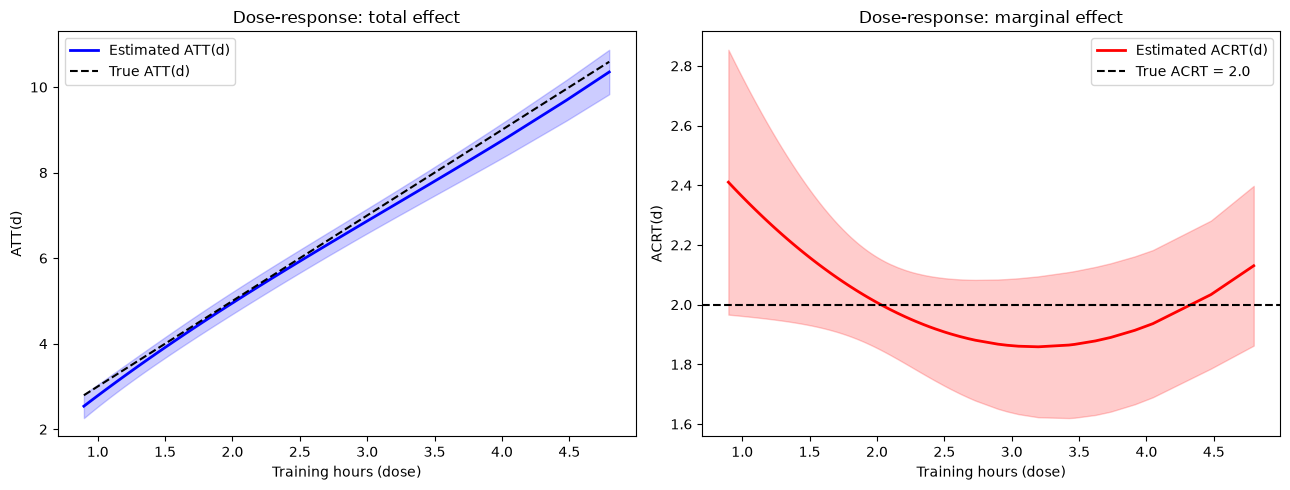

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

att = results.dose_response_att
axes[0].plot(att.dose_grid, att.effects, "b-", linewidth=2, label="Estimated ATT(d)")
axes[0].fill_between(att.dose_grid, att.conf_int_lower, att.conf_int_upper, alpha=0.2, color="blue")
axes[0].plot(att.dose_grid, ATT_INTERCEPT + ATT_SLOPE * att.dose_grid, "k--", linewidth=1.5, label="True ATT(d)")
axes[0].set_xlabel("Training hours (dose)")
axes[0].set_ylabel("ATT(d)")
axes[0].set_title("Dose-response: total effect")
axes[0].legend()

acrt = results.dose_response_acrt
axes[1].plot(acrt.dose_grid, acrt.effects, "r-", linewidth=2, label="Estimated ACRT(d)")
axes[1].fill_between(acrt.dose_grid, acrt.conf_int_lower, acrt.conf_int_upper, alpha=0.2, color="red")
axes[1].axhline(ATT_SLOPE, color="k", linestyle="--", linewidth=1.5, label="True ACRT = 2.0")
axes[1].set_xlabel("Training hours (dose)")
axes[1].set_ylabel("ACRT(d)")
axes[1].set_title("Dose-response: marginal effect")
axes[1].legend()

plt.tight_layout()
plt.show()

- **Left, ATT(d):** the estimated total effect rises almost linearly and tracks the true
  curve. At a dose of about 3 hours the estimate is 6.96 against a true 7.10.
- **Right, ACRT(d):** the estimated return to an extra hour stays close to the true value
  of 2. Its band is wider at the ends of the dose range, where there are few workers,
  and the derivative of a curve is always harder to pin down than the curve.

The grid runs from 0.90 to 4.80 hours, although one worker received 7.08. The 99th
percentile is where the default grid stops evaluating, not where the data end: doses
above it are observed, but by few workers, so the curve is poorly determined there.
Pass `dvals` to choose your own evaluation points, and keep them inside the range of
doses you observe.

Both panels rest on **strong parallel trends**. It holds here because doses were
assigned at random. Under parallel trends alone only the overall ATT has a causal
reading.

## Event study

`aggregate("event_study")` treats training as binary and reports the overall effect by
time since training started. Its pre-treatment coefficients are the place to look for
evidence on parallel trends. An event study is more informative with several cohorts, so
this section uses a second simulated panel with cohorts starting in periods 3 and 5.

In [8]:
two_cohorts = generate_continuous_did_data(
    n_units=500,
    n_periods=6,
    cohort_periods=[3, 5],
    never_treated_frac=0.3,
    att_function="linear",
    att_intercept=ATT_INTERCEPT,
    att_slope=ATT_SLOPE,
    seed=42,
)

results_two_cohorts = ContinuousDiD(seed=42).fit(two_cohorts, **fit_args)
es = results_two_cohorts.aggregate("event_study")

columns = ["event_time", "att", "se", "conf_int_lower", "conf_int_upper", "is_reference"]
print(es.to_dataframe()[columns].round(3).to_string(index=False))

 event_time    att    se  conf_int_lower  conf_int_upper  is_reference
         -3 -0.088 0.154          -0.390           0.213         False
         -2  0.053 0.152          -0.245           0.351         False
         -1 -0.120 0.113          -0.342           0.103         False
          0  4.697 0.151           4.402           4.992         False
          1  4.727 0.138           4.456           4.998         False
          2  4.587 0.212           4.173           5.002         False
          3  4.609 0.210           4.197           5.020         False


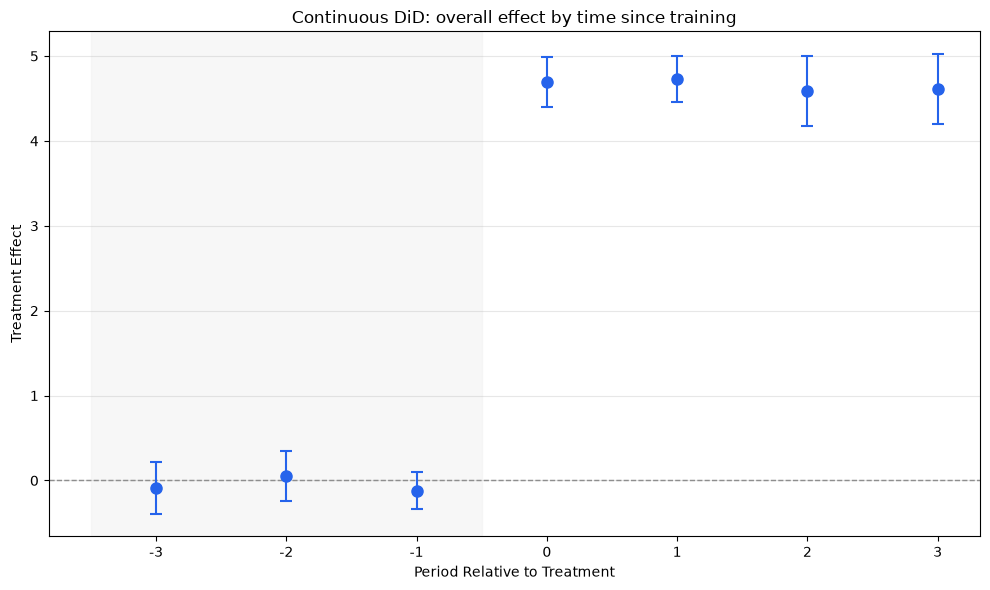

In [9]:
ax = plot_event_study(es, title="Continuous DiD: overall effect by time since training", show=False)

The three pre-treatment estimates are within about one standard error of zero, and the
post-treatment estimates are stable around 4.6 to 4.7. As always, that is the absence of
visible evidence against parallel trends, not proof of it, and it says nothing about
*strong* parallel trends, which concerns outcomes under treatment and has no
pre-treatment counterpart to inspect. See
[Pre-Trends Power](07_pretrends_power.ipynb) for what such a check can detect.

There is no reference row in the table. With the default `base_period="varying"`, each
pre-treatment estimate compares one period with the period before it. Use
`base_period="universal"` to measure every period against the same pre-treatment
period. For a sensitivity analysis, fit `CallawaySantAnna(base_period="universal")` on
the binary treatment and pass its event study to [Honest DiD](05_honest_did.ipynb): the
event study of a `ContinuousDiD` fit is not accepted there.

## Options

### Spline flexibility

The dose-response function is approximated with B-splines:

- **`degree`** sets the smoothness: 1 is piecewise linear, 3 (the default) is cubic.
- **`num_knots`** adds interior knots, letting the curve bend at more points.

To see what they do, the next cell uses data where the true curve is not a straight
line: ATT(d) = 1 + 2 log(1 + d).

In [10]:
log_data = generate_continuous_did_data(
    n_units=500,
    n_periods=4,
    cohort_periods=[2],
    never_treated_frac=0.3,
    att_function="log",
    att_intercept=1.0,
    att_slope=2.0,
    seed=42,
)
log_doses = log_data.loc[log_data["first_treat"] > 0].groupby("unit")["dose"].first()
true_log_att = (1.0 + 2.0 * np.log1p(log_doses)).mean()
true_log_acrt = (2.0 / (1.0 + log_doses)).mean()

configurations = {
    "Linear (degree=1, no knots)": dict(degree=1, num_knots=0),
    "Cubic (degree=3, no knots)": dict(degree=3, num_knots=0),
    "Cubic, 2 knots": dict(degree=3, num_knots=2),
}

spline_fits = {}
print(f"{'Configuration':<30} {'overall ATT':>12} {'overall ACRT':>13} {'ACRT SE':>9}")
for label, settings in configurations.items():
    fit = ContinuousDiD(seed=42, **settings).fit(log_data, **fit_args)
    spline_fits[label] = fit
    print(f"{label:<30} {fit.att:>12.3f} {fit.overall_acrt:>13.3f} {fit.overall_acrt_se:>9.3f}")
print(f"{'Truth':<30} {true_log_att:>12.3f} {true_log_acrt:>13.3f}")

Configuration                   overall ATT  overall ACRT   ACRT SE
Linear (degree=1, no knots)           2.862         0.672     0.060
Cubic (degree=3, no knots)            2.862         0.910     0.097
Cubic, 2 knots                        2.862         0.965     0.106
Truth                                 2.990         0.771


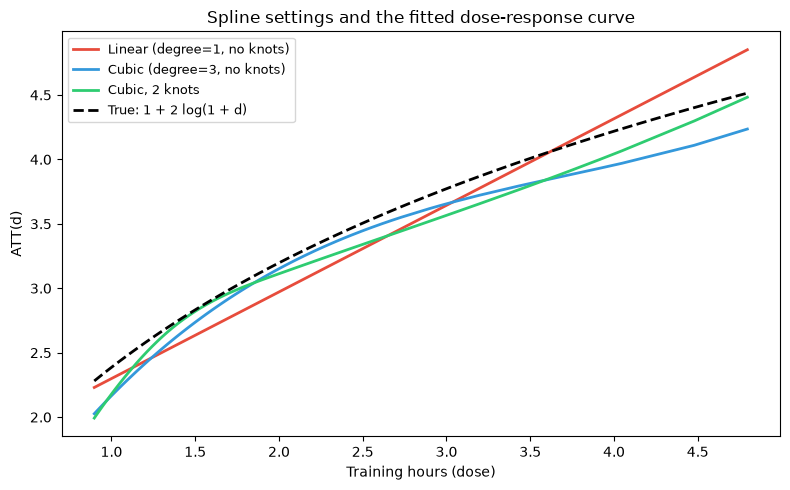

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))

for (label, fit), color in zip(spline_fits.items(), ["#e74c3c", "#3498db", "#2ecc71"]):
    curve = fit.dose_response_att
    ax.plot(curve.dose_grid, curve.effects, color=color, linewidth=2, label=label)

dose_range = np.linspace(log_doses.quantile(0.10), log_doses.quantile(0.99), 100)
ax.plot(dose_range, 1.0 + 2.0 * np.log1p(dose_range), "k--", linewidth=2, label="True: 1 + 2 log(1 + d)")
ax.set_xlabel("Training hours (dose)")
ax.set_ylabel("ATT(d)")
ax.set_title("Spline settings and the fitted dose-response curve")
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

Three things to take from this.

- The **overall ATT does not depend on the spline** at all: it is the binary comparison,
  and it is 2.86 in every row.
- The **curve** does. The straight line cannot follow the concave true curve; the cubic
  fits bend with it.
- More flexibility is **not automatically closer to the truth** for the overall ACRT.
  The linear fit understates it (0.67 against a true 0.77) and both cubic fits overstate
  it (0.91 and 0.97), each by somewhat more than one standard error, and the standard
  error grows with flexibility. A slope is a demanding thing to estimate from 350
  workers.

In practice: plot the curve, start from a simple specification, add flexibility only
where the plot shows the simple one failing, and report how the answer moves.

### Control group

`control_group` selects the comparison units:

- **`"never_treated"`** (default): units that are never treated. Parallel trends is then
  an assumption about that one group.
- **`"not_yet_treated"`**: also units that will be treated later, in the periods before
  they are. This uses more data and additionally requires that the later-treated units
  were on the same path, and were not already responding, before their own treatment.
- **`"lowest_dose"`**: when nobody is untreated, the lowest-dose group is the
  comparison, and effects are measured relative to it.

The first two are different assumptions, not a weaker and a stronger version of one.

In [12]:
print(f"{'Control group':<17} {'overall ATT':>12} {'SE':>7} {'overall ACRT':>13} {'SE':>7}")
for control_group in ["never_treated", "not_yet_treated"]:
    fit = ContinuousDiD(control_group=control_group, seed=42).fit(two_cohorts, **fit_args)
    print(
        f"{control_group:<17} {fit.att:>12.3f} {fit.se:>7.3f} "
        f"{fit.overall_acrt:>13.3f} {fit.overall_acrt_se:>7.3f}"
    )

Control group      overall ATT      SE  overall ACRT      SE
never_treated            4.707   0.137         1.901   0.103
not_yet_treated          4.709   0.136         1.901   0.103


Here the two give the same answer to two decimals. With two cohorts and a large
never-treated group, the not-yet-treated units add little.

### Bootstrap inference

Standard errors are analytical by default. Setting `n_bootstrap` switches to a
multiplier bootstrap, which perturbs each unit's contribution with random weights
(`bootstrap_weights`: `"rademacher"` by default, `"mammen"` or `"webb"`). It is an
alternative way to compute the same uncertainty, useful as a cross-check and for
intervals that do not rely on a normal approximation; 999 draws with a fixed seed is
the standard here.

In [13]:
bootstrapped = ContinuousDiD(n_bootstrap=999, seed=42).fit(data, **fit_args)

print(f"{'Inference':<12} {'overall ATT':>12} {'SE':>7} {'95% CI':>20}")
for label, fit in [("Analytical", results), ("Bootstrap", bootstrapped)]:
    print(f"{label:<12} {fit.att:>12.3f} {fit.se:>7.3f} {f'[{fit.conf_int[0]:.3f}, {fit.conf_int[1]:.3f}]':>20}")

print()
print(f"{'Inference':<12} {'overall ACRT':>12} {'SE':>7} {'95% CI':>20}")
for label, fit in [("Analytical", results), ("Bootstrap", bootstrapped)]:
    lower, upper = fit.overall_acrt_conf_int
    print(f"{label:<12} {fit.overall_acrt:>12.3f} {fit.overall_acrt_se:>7.3f} {f'[{lower:.3f}, {upper:.3f}]':>20}")

Inference     overall ATT      SE               95% CI
Analytical          4.547   0.157       [4.238, 4.855]
Bootstrap           4.547   0.164       [4.244, 4.872]

Inference    overall ACRT      SE               95% CI
Analytical          2.149   0.097       [1.958, 2.339]
Bootstrap           2.149   0.096       [1.959, 2.340]


The two agree closely: standard errors of 0.157 and 0.164 for the overall ATT, and 0.097
and 0.096 for the overall ACRT.

## What a binary analysis loses

Ignore the dose and run Callaway-Sant'Anna on trained against untrained workers. With
one cohort it returns the same overall ATT, and nothing else. With staggered cohorts
the two overall numbers differ, because they average the cohort-period effects with
different weights.

In [14]:
binary = CallawaySantAnna(control_group="never_treated").fit(
    data, outcome="outcome", unit="unit", time="period", first_treat="first_treat"
)

binary_two_cohorts = CallawaySantAnna(control_group="never_treated").fit(
    two_cohorts, outcome="outcome", unit="unit", time="period", first_treat="first_treat"
)

print(f"{'Panel':<13} {'Estimator':<18} {'overall ATT':>12} {'SE':>8}")
for panel, continuous_fit, binary_fit in [
    ("one cohort", results, binary),
    ("two cohorts", results_two_cohorts, binary_two_cohorts),
]:
    print(f"{panel:<13} {'ContinuousDiD':<18} {continuous_fit.att:>12.4f} {continuous_fit.se:>8.4f}")
    print(f"{panel:<13} {'CallawaySantAnna':<18} {binary_fit.att:>12.4f} {binary_fit.se:>8.4f}")

Panel         Estimator           overall ATT       SE
one cohort    ContinuousDiD            4.5468   0.1575
one cohort    CallawaySantAnna         4.5468   0.1575
two cohorts   ContinuousDiD            4.7070   0.1370
two cohorts   CallawaySantAnna         4.6741   0.1413


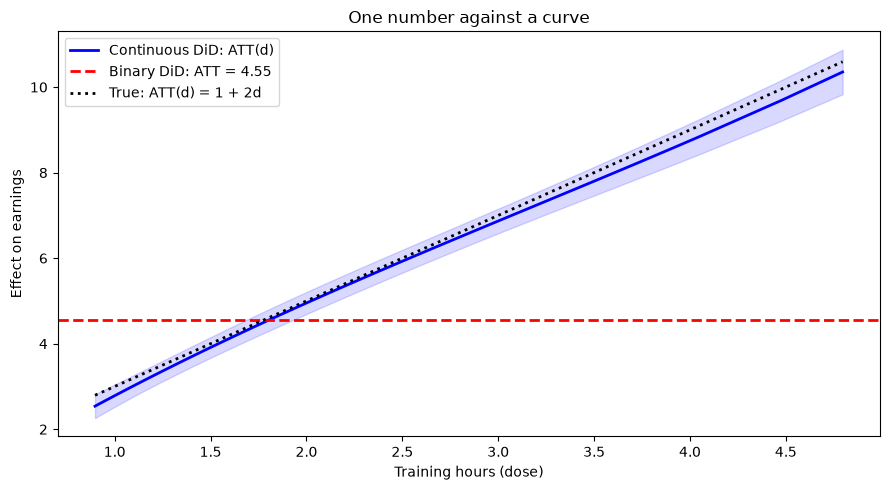

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))

att = results.dose_response_att
ax.plot(att.dose_grid, att.effects, "b-", linewidth=2, label="Continuous DiD: ATT(d)")
ax.fill_between(att.dose_grid, att.conf_int_lower, att.conf_int_upper, alpha=0.15, color="blue")
ax.axhline(binary.att, color="red", linestyle="--", linewidth=2, label=f"Binary DiD: ATT = {binary.att:.2f}")
ax.plot(att.dose_grid, ATT_INTERCEPT + ATT_SLOPE * att.dose_grid, "k:", linewidth=2, label="True: ATT(d) = 1 + 2d")
ax.set_xlabel("Training hours (dose)")
ax.set_ylabel("Effect on earnings")
ax.set_title("One number against a curve")
ax.legend()

plt.tight_layout()
plt.show()

On the one-cohort panel the two overall ATTs are the same number, standard error
included: with a single cohort the continuous estimator's overall ATT *is* the binary
comparison.

On the two-cohort panel they differ, 4.71 against 4.67, although both average the same
cohort-period effects. `ContinuousDiD` averages each cohort over its post-treatment
periods and then weights the cohorts by size. Callaway-Sant'Anna's overall ATT weights
every cohort-period cell by cohort size, so a cohort with more post-treatment periods
counts for more: here the earlier cohort has four and the later one two. They are
different averages, and neither is the wrong one.

What the binary analysis cannot give is everything else in this tutorial. Its single
number, 4.55 on the one-cohort panel, is the average effect at
the doses workers happened to receive. It cannot say that a worker with one hour gains
about 3 and a worker with four hours about 9, or what an extra hour is worth.

## Exporting results

`to_dataframe(level=...)` returns the dose-response curve (`"dose_response"`, the
default), the underlying group-time estimates (`"group_time"`), or the event study
(`"event_study"`).

In [16]:
print(results.to_dataframe(level="dose_response").head().round(3).to_string(index=False))
print()
print(results.to_dataframe(level="group_time").round(3).to_string(index=False))

 dose   att  att_se  att_ci_lower  att_ci_upper  acrt  acrt_se  acrt_ci_lower  acrt_ci_upper
0.897 2.539   0.142         2.261         2.818 2.410    0.226          1.967          2.854
0.913 2.577   0.140         2.302         2.852 2.403    0.223          1.966          2.840
0.933 2.626   0.138         2.355         2.897 2.393    0.218          1.965          2.821
0.950 2.665   0.137         2.397         2.933 2.385    0.215          1.964          2.807
0.973 2.721   0.135         2.457         2.985 2.374    0.210          1.963          2.785

 group  time  att_glob  acrt_glob  n_treated  n_control
     2     2     4.398      2.104        350        150
     2     3     4.604      2.141        350        150
     2     4     4.638      2.201        350        150


## Summary

- With a continuous treatment there are several parameters. The overall ATT needs
  parallel trends; the dose-response curve ATT(d), its slope ACRT(d) and any comparison
  across doses need strong parallel trends, which rules out selection into dose on
  gains.
- `ContinuousDiD` estimates the overall parameters and both curves in one fit, with a
  B-spline for the shape of the curve.
- The event study is the binary one: use its pre-treatment coefficients as evidence on
  parallel trends, with the usual caution.
- A binary analysis recovers the same overall ATT when there is one cohort, a
  differently weighted average when adoption is staggered, and none of the dose-response
  information.

## When to use it and when not to

Use it when treatment has an intensity that is fixed for each unit, there is an untreated
(or lowest-dose) comparison group, and the question is about the dose. Report the
overall ATT under parallel trends, and present the curve with a clear statement that it
rests on strong parallel trends. Do not read the curve causally when units plausibly
chose their dose according to expected benefit, and do not use it for a dose that
changes over time within a unit.

### Parameter reference

| Parameter | Default | Description |
|---|---|---|
| `degree` | 3 | B-spline degree (1 = linear, 3 = cubic) |
| `num_knots` | 0 | Interior knots |
| `dvals` | `None` | Doses at which to evaluate the curves (default: percentiles 10 to 99) |
| `control_group` | `"never_treated"` | `"never_treated"`, `"not_yet_treated"` or `"lowest_dose"` |
| `treatment_type` | `"continuous"` | `"continuous"` or `"discrete"` doses |
| `anticipation` | 0 | Periods of anticipation |
| `base_period` | `"varying"` | `"varying"` or `"universal"` |
| `n_bootstrap` | 0 | Bootstrap draws (0 = analytical standard errors) |
| `bootstrap_weights` | `"rademacher"` | `"rademacher"`, `"mammen"` or `"webb"` |
| `seed` | `None` | Random seed |

## Next steps

- [HAD Brand Campaign](20_had_brand_campaign.ipynb): a continuous treatment when every
  unit is treated
- [Staggered DiD](02_staggered_did.ipynb): the binary estimator used for comparison
- [Honest DiD Sensitivity](05_honest_did.ipynb): results under bounded violations of
  parallel trends

## References

- Callaway, B., Goodman-Bacon, A., & Sant'Anna, P. H. C. (2024). "Difference-in-Differences
  with a Continuous Treatment." NBER Working Paper 32117.